<a href="https://colab.research.google.com/github/SamuelSfy/Prediction-affluence-sur-lignes-de-bus-Cas-de-Saint-Sebastien-Espagne/blob/main/Prediction_d'affluence_sur_les_lignes_de_bus_a_Saint_Sebastien.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# pip install xgboost==1.6.2 scikit-learn==1.0.2


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


/usr/local/lib/python3.10/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')
data = pd.read_csv("/content/gdrive/MyDrive/Colab Notebooks/data_passagers.csv")

Mounted at /content/gdrive


In [ ]:
data.head(100)

,dateTime,weather,lineNumber,passengersNumber,lineType
0,2019-04-05,26,29,3032,daily
1,2019-04-05,26,42,418,daily
2,2019-04-05,26,40,2065,daily
3,2019-04-05,26,104,115,night
4,2019-04-05,26,27,2900,daily
...,...,...,...,...,...
95,2019-04-07,25,23,199,daily
96,2019-04-07,25,9,1807,daily
97,2019-04-07,25,32,242,daily
98,2019-04-07,25,36,476,daily


In [ ]:
data.describe()

,weather,lineNumber,passengersNumber
count,37621.000000,37621.000000,37621.000000
mean,24.010579,31.744903,2067.940990
std,11.734847,23.335248,2494.733418
min,11.000000,5.000000,1.000000
25%,13.000000,17.000000,365.000000
50%,24.000000,28.000000,1241.000000
75%,26.000000,38.000000,2558.000000
max,62.000000,110.000000,16124.000000


In [ ]:
data.isnull().any()

,0
dateTime,False
weather,False
lineNumber,False
passengersNumber,False
lineType,False


In [ ]:
data.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
37616,False
37617,False
37618,False
37619,False


In [ ]:
data['lineType']=data['lineType'].map({"daily":1,"night":0})
data

,dateTime,weather,lineNumber,passengersNumber,lineType
0,2019-04-05,26,29,3032,1
1,2019-04-05,26,42,418,1
2,2019-04-05,26,40,2065,1
3,2019-04-05,26,104,115,0
4,2019-04-05,26,27,2900,1
...,...,...,...,...,...
37616,2023-03-19,26,26,2650,1
37617,2023-03-19,26,31,905,1
37618,2023-03-19,26,36,425,1
37619,2023-03-19,26,41,273,1


# Notebook de Prédiction d'Affluence de Bus

Ce notebook explore les relations dans le dataset concernant le nombre de passagers des lignes de bus.

## 1. Tendances Temporelles
### Affluence par Date
Visualiser les tendances des passagers au fil du temps permet d'identifier les périodes de forte et faible affluence. Cela aide à prévoir les besoins en capacité de transport et à ajuster les horaires ou la fréquence des bus.

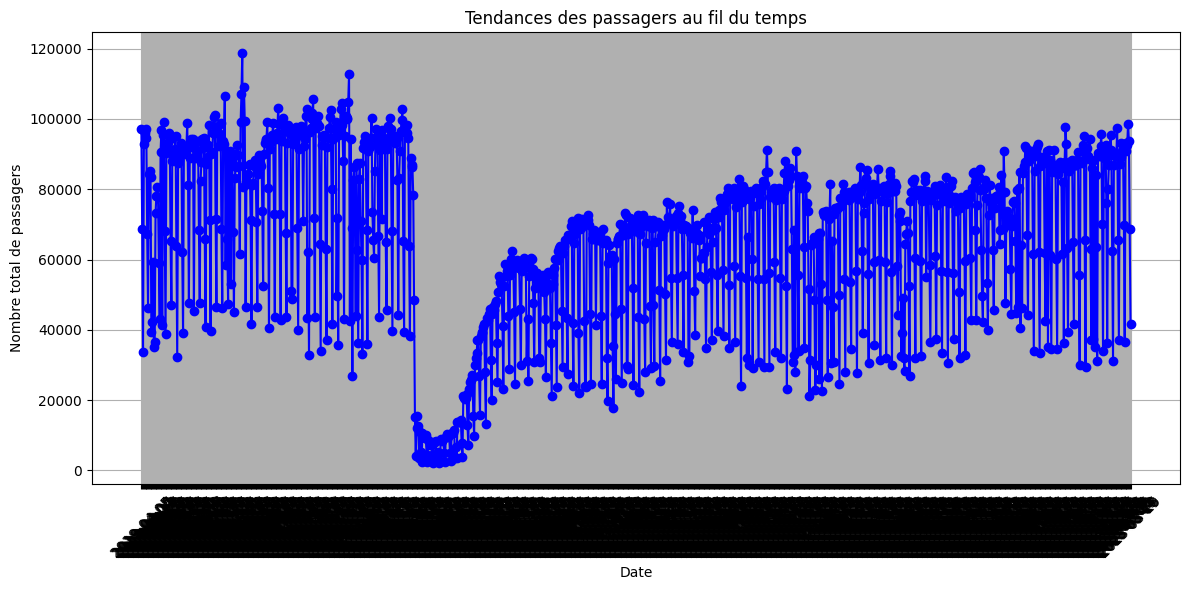

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Groupement par date et somme des passagers
daily_passengers = data.groupby('dateTime')['passengersNumber'].sum()

# Visualisation
plt.figure(figsize=(12, 6))
plt.plot(daily_passengers.index, daily_passengers.values, marker='o', linestyle='-', color='blue')
plt.title('Tendances des passagers au fil du temps')
plt.xlabel('Date')
plt.ylabel('Nombre total de passagers')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

<ipython-input-11-38764f564da7>:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_passengers = data.resample('M', on='dateTime')['passengersNumber'].sum()


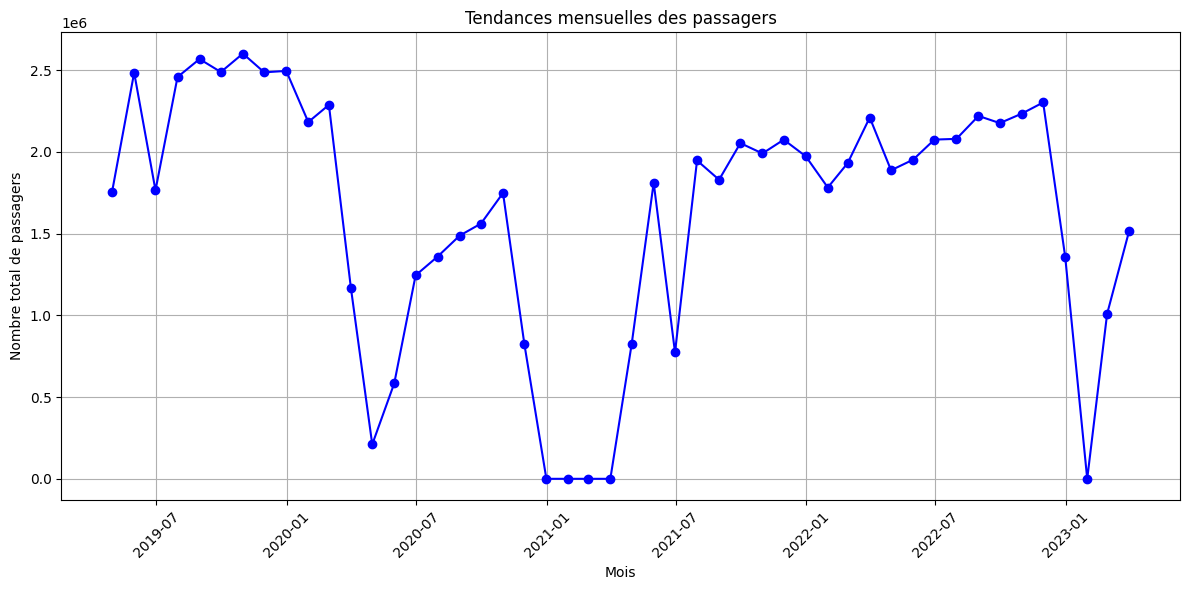

In [ ]:
# Agrégation par mois
# Convert 'dateTime' column to datetime objects
data['dateTime'] = pd.to_datetime(data['dateTime'])

monthly_passengers = data.resample('M', on='dateTime')['passengersNumber'].sum()

# Visualisation
plt.figure(figsize=(12, 6))
plt.plot(monthly_passengers.index, monthly_passengers.values, marker='o', linestyle='-', color='blue')
plt.title('Tendances mensuelles des passagers')
plt.xlabel('Mois')
plt.ylabel('Nombre total de passagers')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

## 2. Comparaison des Lignes de Bus
### Affluence par Ligne
Comprendre quelles lignes de bus attirent le plus de passagers est crucial pour optimiser les ressources.

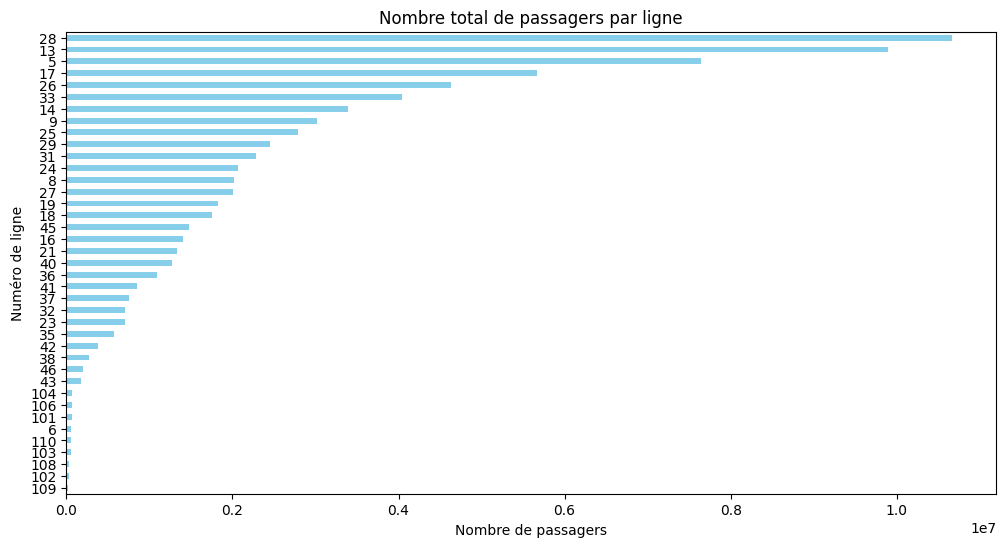

In [ ]:
# Affluence par ligne
plt.figure(figsize=(12, 6))
line_passengers = data.groupby('lineNumber')['passengersNumber'].sum().sort_values()
line_passengers.plot(kind='barh', color='skyblue')
plt.title('Nombre total de passagers par ligne')
plt.xlabel('Nombre de passagers')
plt.ylabel('Numéro de ligne')
plt.show()

10 Lignes de bus les plus empruntés

In [ ]:
top_lines = line_passengers.nlargest(10)
top_lines_df = top_lines.reset_index()

<Axes: xlabel='lineNumber', ylabel='passengersNumber'>

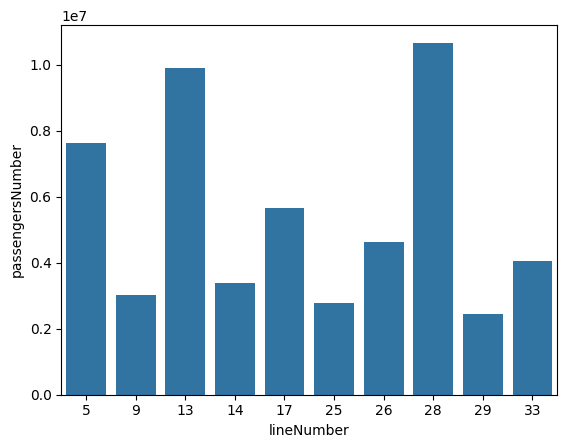

In [ ]:
sns.barplot(top_lines_df,x='lineNumber',y='passengersNumber')

AFFLUENCE PAR TYPE DE LIGNE(NUIT OU JOUR)

<Figure size 800x500 with 0 Axes>

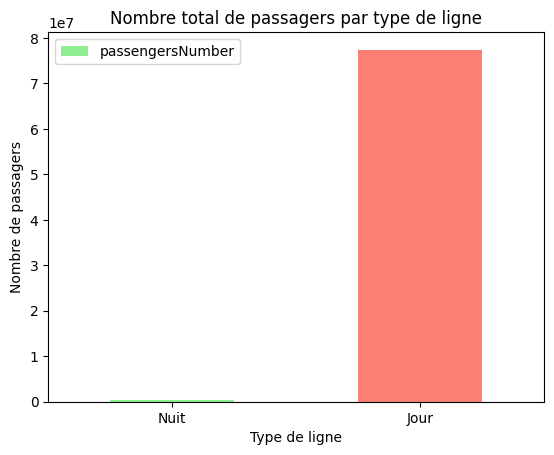

In [ ]:
# Affluence par type de ligne
plt.figure(figsize=(8, 5))
type_passengers = data.groupby('lineType')['passengersNumber'].sum().reset_index()
type_passengers['lineType'] = type_passengers['lineType'].map({1: "Jour", 0: "Nuit"})
type_passengers.plot(kind='bar', x='lineType', y='passengersNumber', color=['lightgreen', 'salmon'])
plt.title('Nombre total de passagers par type de ligne')
plt.xlabel('Type de ligne')
plt.ylabel('Nombre de passagers')
plt.xticks(rotation=0)
plt.show()

## 3. Impact Météorologique
### Corrélation entre Météo et Passagers
Comprendre l'impact des conditions météorologiques sur l'affluence est essentiel pour la planification des opérations.

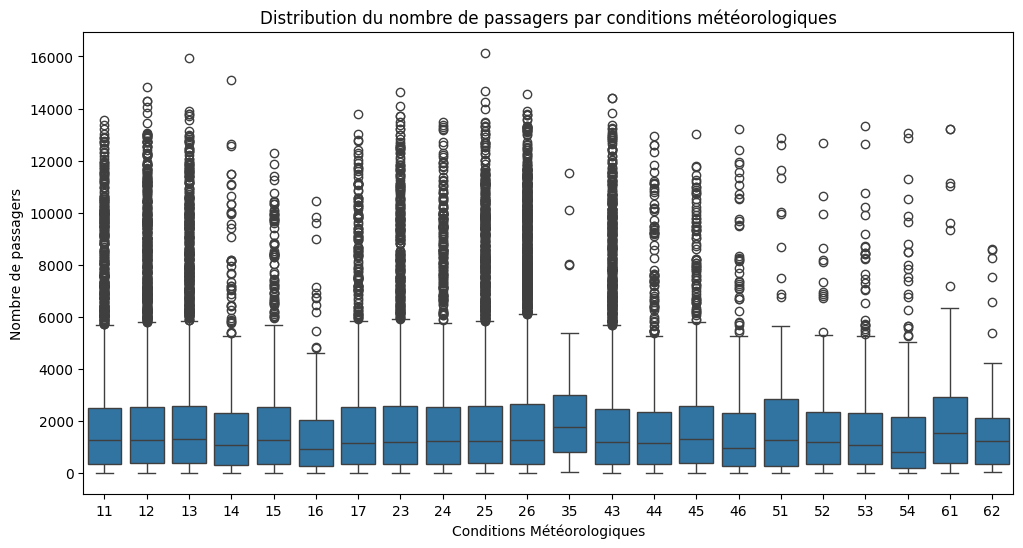

In [ ]:
# Corrélation entre météo et passagers
plt.figure(figsize=(12, 6))
import seaborn as sns
sns.boxplot(x='weather', y='passengersNumber', data=data)
plt.title('Distribution du nombre de passagers par conditions météorologiques')
plt.xlabel('Conditions Météorologiques')
plt.ylabel('Nombre de passagers')
plt.show()

Text(0.5, 1.0, 'nombre de passagers par conditions météorologiques')

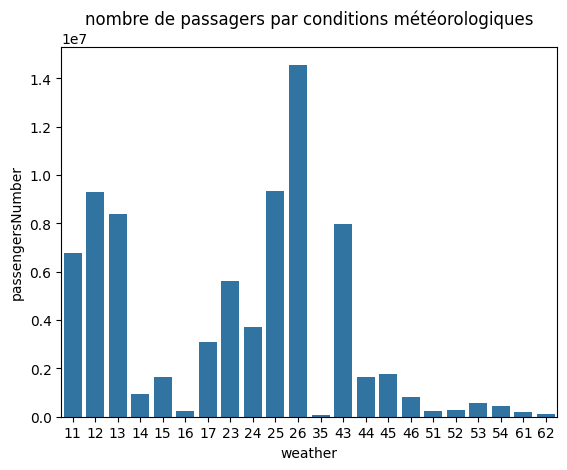

In [ ]:
pass_wheater=data.groupby('weather')['passengersNumber'].sum().reset_index()
sns.barplot(pass_wheater,x='weather',y='passengersNumber')
plt.title('nombre de passagers par conditions météorologiques')


NOMBRE DE PASSAGERS PAR MOIS(2019-2023)

In [ ]:
data['dateTimeMonth']=data['dateTime'].dt.month

In [ ]:
data

,dateTime,weather,lineNumber,passengersNumber,lineType,dateTimeMonth
0,2019-04-05,26,29,3032,1,4
1,2019-04-05,26,42,418,1,4
2,2019-04-05,26,40,2065,1,4
3,2019-04-05,26,104,115,0,4
4,2019-04-05,26,27,2900,1,4
...,...,...,...,...,...,...
37616,2023-03-19,26,26,2650,1,3
37617,2023-03-19,26,31,905,1,3
37618,2023-03-19,26,36,425,1,3
37619,2023-03-19,26,41,273,1,3


In [ ]:
month_passagers=data.groupby('dateTimeMonth')['passengersNumber'].sum().reset_index()

Text(0.5, 1.0, 'Nombre total de passagers par mois')

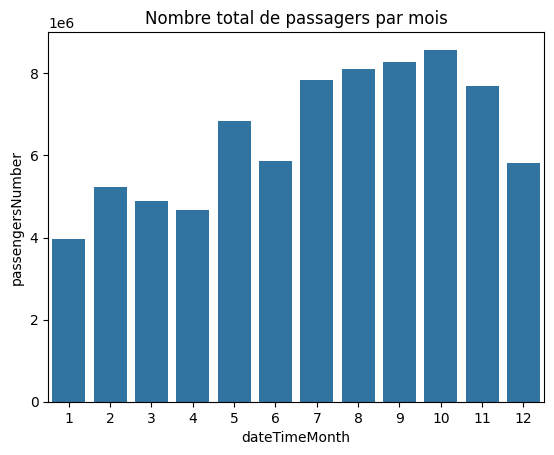

In [ ]:
sns.barplot(month_passagers,x='dateTimeMonth',y='passengersNumber')
plt.title('Nombre total de passagers par mois')

**Nombre de passagers dans les differents mois d'une année précise**

Text(0.5, 1.0, 'Nombre total de passagers par mois en 2021')

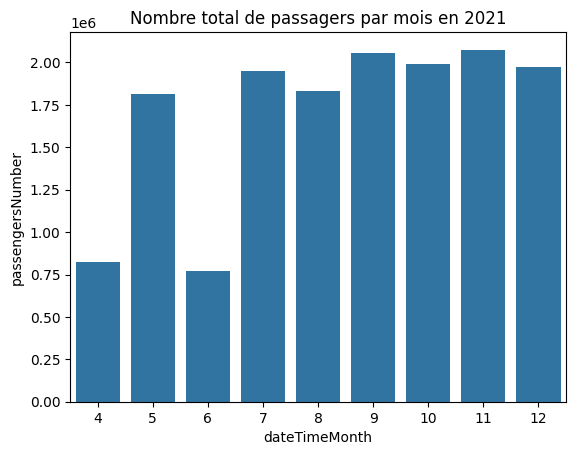

In [ ]:
data['dateTimeYear']=data['dateTime'].dt.year
month_passagers_year=data[data['dateTimeYear']==2021]
month_year_pass=month_passagers_year.groupby('dateTimeMonth')['passengersNumber'].sum().reset_index()
sns.barplot(month_year_pass,x='dateTimeMonth',y='passengersNumber')
plt.title('Nombre total de passagers par mois en 2021')

**l'affluence des passagers dans les jours de la semaine (2019-2023)**

Text(0.5, 1.0, 'Nombre total de passagers dans les jours de la semaine')

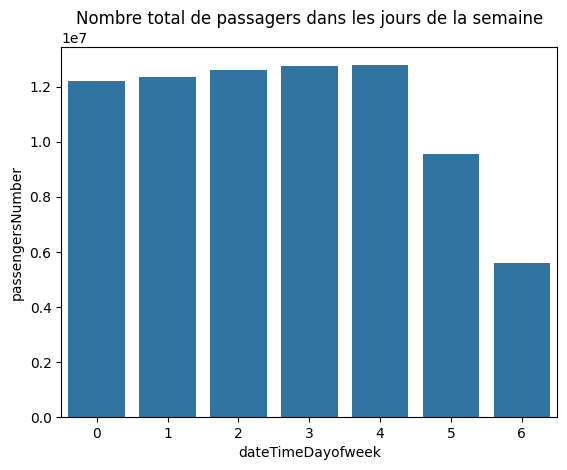

In [ ]:
data['dateTimeDayofweek']=data['dateTime'].dt.weekday
day_passenger_week=data.groupby('dateTimeDayofweek')['passengersNumber'].sum().reset_index()
sns.barplot(day_passenger_week,x='dateTimeDayofweek',y='passengersNumber')
plt.title('Nombre total de passagers dans les jours de la semaine')


**L'affluence des passagers dans la semaine pour mois choisi**

Text(0.5, 1.0, 'Nombre total de passagers dans la semaine pour un mois précis')

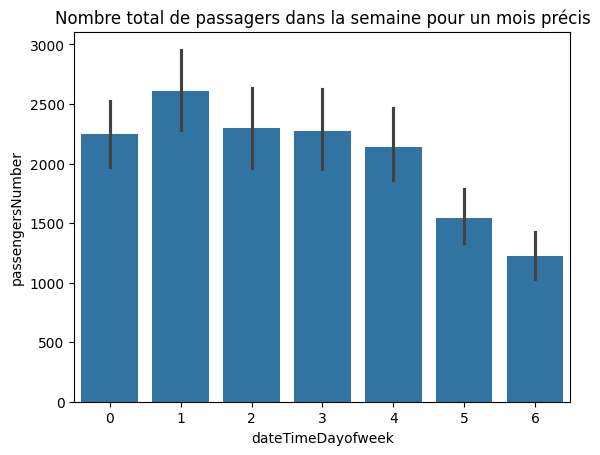

In [ ]:
month_choose=data[data['dateTimeMonth']==1]
day_pass_month_choose=month_choose.groupby('dateTimeDayofweek')['passengersNumber'].sum().reset_index()
sns.barplot(month_choose,x='dateTimeDayofweek',y='passengersNumber')
plt.title('Nombre total de passagers dans la semaine pour un mois précis')

Text(0.5, 1.0, 'Nombre de passagers par année')

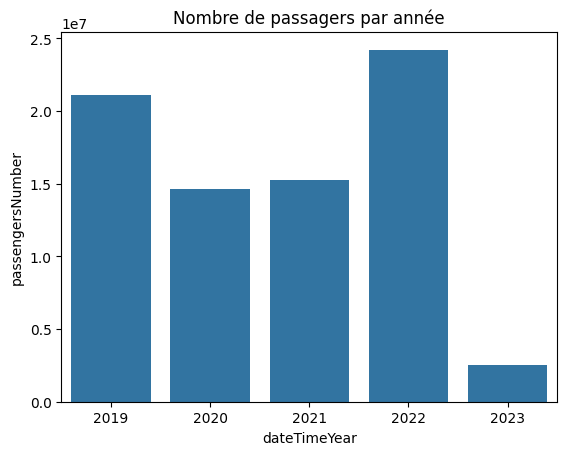

In [ ]:
dateTimeWeek_pass=data.groupby('dateTimeYear')['passengersNumber'].sum().reset_index()
sns.barplot(dateTimeWeek_pass,x='dateTimeYear',y='passengersNumber')
plt.title('Nombre de passagers par année')

## 4. Corrélations entre Caractéristiques
### Matrice de Corrélation
Analyser les corrélations entre différentes variables aide à identifier des facteurs influents sur le nombre de passagers.

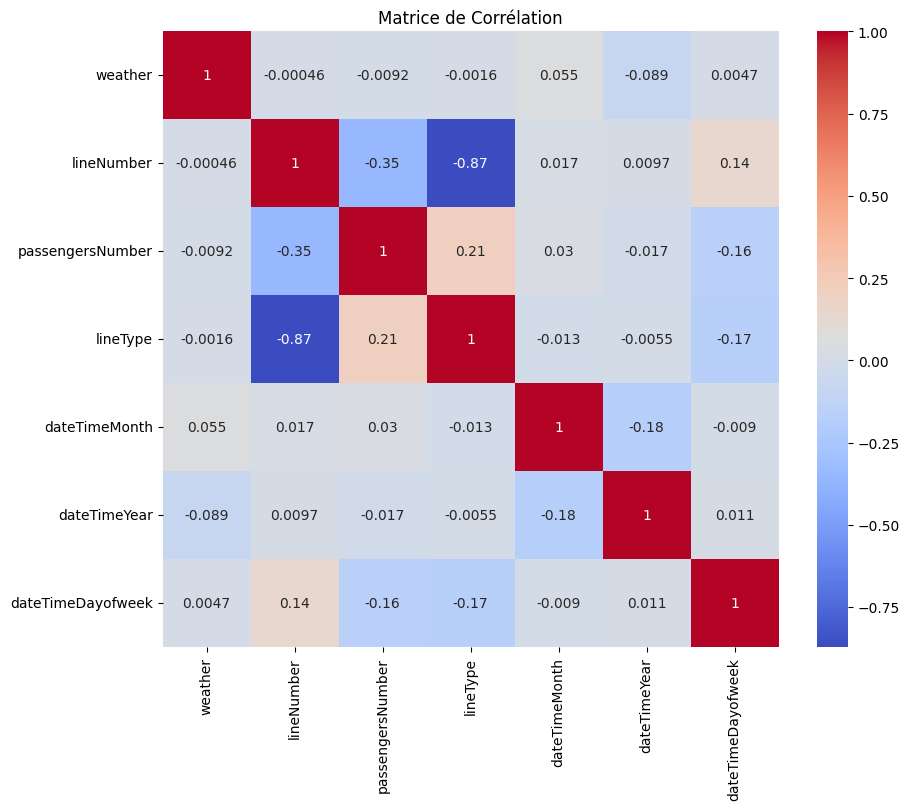

In [ ]:
# Matrice de corrélation
plt.figure(figsize=(10, 8))
# Exclude non-numeric columns before calculating correlation
correlation_matrix = data.select_dtypes(include=['number']).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', square=True)
plt.title('Matrice de Corrélation')
plt.show()

## 5. Valeurs Aberrantes
### Identification de Pics
Les valeurs aberrantes dans le nombre de passagers peuvent indiquer des événements spéciaux qui attirent une affluence importante.

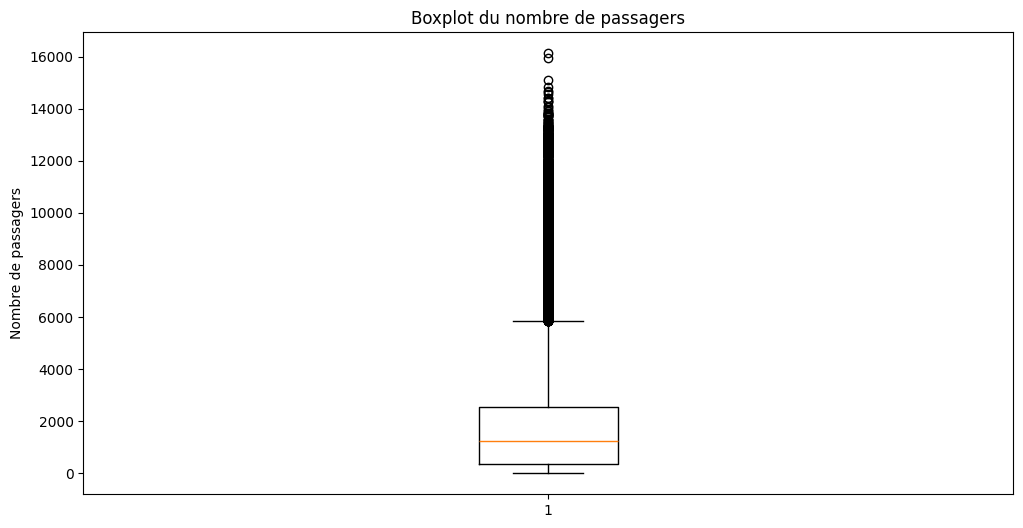

In [ ]:
# Valeurs aberrantes
plt.figure(figsize=(12, 6))
plt.boxplot(data['passengersNumber'])
plt.title('Boxplot du nombre de passagers')
plt.ylabel('Nombre de passagers')
plt.show()

## 6. Visualisation des Relations Temporelles et des Lignes
### Heatmap du Nombre de Passagers par Date et Ligne
Cette visualisation offre une vue d'ensemble des comportements des passagers sur différentes lignes à différents moments.

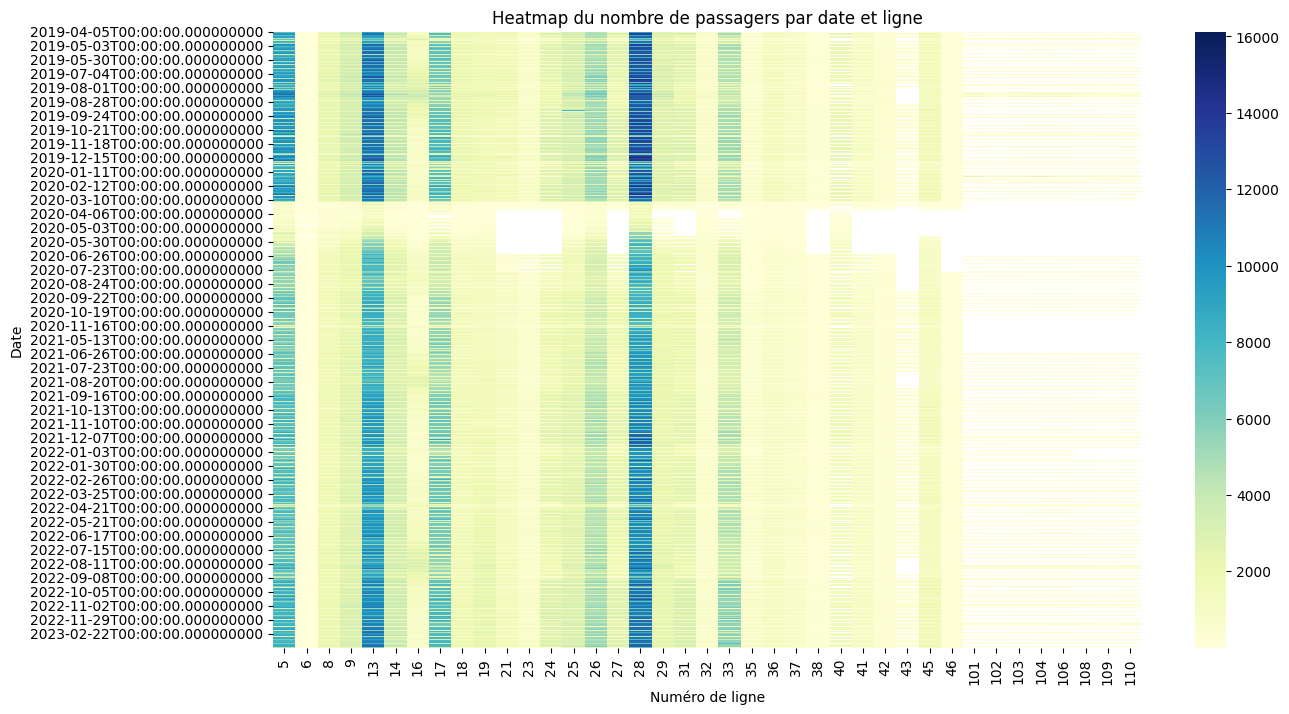

In [ ]:
# Création d'une table pivot pour la heatmap
pivot_table = data.pivot_table(values='passengersNumber', index='dateTime', columns='lineNumber', aggfunc='sum')

plt.figure(figsize=(14, 8))
sns.heatmap(pivot_table, cmap='YlGnBu')
plt.title('Heatmap du nombre de passagers par date et ligne')
plt.xlabel('Numéro de ligne')
plt.ylabel('Date')
plt.show()

**Ajout de features important à partir de la date**

In [ ]:
data['dateTimeWeek ']=data['dateTime'].dt.isocalendar().week
data['dateTimeDay']=data['dateTime'].dt.day
data['dateTimeDayofyear']=data['dateTime'].dt.dayofyear

In [ ]:
# data = data.sort_values(by=['lineNumber', 'dateTime'])
# data['nbPassenger_lag1']=data.groupby('lineNumber')['passengersNumber'].shift(7)
# data['nbPassenger_lag2']=data.groupby('lineNumber')['passengersNumber'].shift(14)
# data['nbPassenger_lag3']=data.groupby('lineNumber')['passengersNumber'].shift(21)
# data['nbPassenger_+3_Days']=data.groupby('lineNumber')['passengersNumber'].shift(-3)

In [ ]:
import pandas as pd
import numpy as np

def calculate_lag_with_year_check(data, line_column, date_column, year_column, value_column, lag_days, fill_method='mean'):
    """
    Calcule les lags tout en vérifiant si la date attendue existe et en gérant les années séparément.

    Args:
        data: DataFrame Pandas avec les colonnes nécessaires.
        line_column: Nom de la colonne indiquant la ligne (ex. : 'lineNumber').
        date_column: Nom de la colonne des dates (ex. : 'dateTime').
        year_column: Nom de la colonne des années (ex. : 'dateTimeYear').
        value_column: Nom de la colonne des valeurs (ex. : 'passengersNumber').
        lag_days: Nombre de jours pour le décalage.
        fill_method: Méthode de remplissage si une date manque ('mean', 'linear', 'ffill').

    Returns:
        DataFrame avec une nouvelle colonne contenant les lags.
    """
    # Créer une colonne pour stocker les lags
    lag_column_name = f"{value_column}_lag{lag_days}" if lag_days > 0 else f"{value_column}_+{abs(lag_days)}_Days"
    data[lag_column_name] = np.nan

    # Boucler sur chaque combinaison (ligne, année)
    for (line_id, year), group in data.groupby([line_column, year_column]):
        group = group.sort_values(by=date_column)  # Trier par date
        for idx, row in group.iterrows():
            expected_date = row[date_column] - pd.Timedelta(days=lag_days)  # Calcul de la date attendue
            lag_value = group.loc[group[date_column] == expected_date, value_column]

            if not lag_value.empty:
                # Si la date est trouvée, utiliser sa valeur
                data.loc[idx, lag_column_name] = lag_value.values[0]
            else:
                # Si la date est manquante, appliquer le remplissage
                if fill_method == 'mean':
                    data.loc[idx, lag_column_name] = group[value_column].mean()
                elif fill_method == 'linear':
                    data.loc[idx, lag_column_name] = group[value_column].interpolate(method='linear').mean()
                elif fill_method == 'ffill':
                    data.loc[idx, lag_column_name] = group[value_column].ffill().iloc[-1]
                else:
                    data.loc[idx, lag_column_name] = np.nan  # Par défaut

        # Arrondir les valeurs des colonnes de lags à l'entier le plus proche
    data[lag_column_name] = data[lag_column_name].round().astype(int)
    return data

# Exemple d'application sur ton dataset
# S'assurer que 'dateTime' est bien de type datetime
data['dateTime'] = pd.to_datetime(data['dateTime'])

# Calcul des lags
lags_to_calculate = [7, 14, 21]  # Lags que tu veux calculer
for lag_days in lags_to_calculate:
    data = calculate_lag_with_year_check(
        data=data,
        line_column='lineNumber',
        date_column='dateTime',
        year_column='dateTimeYear',  # Utilisation de la colonne existante pour l'année
        value_column='passengersNumber',
        lag_days=lag_days,
        fill_method='mean'  # Remplir les valeurs manquantes par la moyenne
    )

# Calcul des valeurs à +3 jours
data = calculate_lag_with_year_check(
    data=data,
    line_column='lineNumber',
    date_column='dateTime',
    year_column='dateTimeYear',  # Utilisation de la colonne existante pour l'année
    value_column='passengersNumber',
    lag_days=-3,  # Décalage vers l'avenir
    fill_method='mean'
)


In [ ]:
# data['nbPassenger_lag1']=data['nbPassenger_lag1'].fillna(data['nbPassenger_lag1'].mean()).round().astype(int)
# data['nbPassenger_lag2']=data['nbPassenger_lag2'].fillna(data['nbPassenger_lag2'].mean()).round().astype(int)
# data['nbPassenger_lag3']=data['nbPassenger_lag3'].fillna(data['nbPassenger_lag3'].mean()).round().astype(int)
# data['nbPassenger_+3_Days']=data['nbPassenger_+3_Days'].fillna(data['nbPassenger_+3_Days'].mean()).round().astype(int)

In [ ]:
# Filtrer les données pour la ligne 5
line_5_data = data[data['lineNumber'] == 21]

# Afficher les premières lignes pour vérifier les lags
print(line_5_data[['dateTime', 'lineNumber','passengersNumber', 'passengersNumber_lag7']].head(15))


      dateTime  lineNumber  passengersNumber  passengersNumber_lag7
18  2019-04-05          21              1608                   1523
42  2019-04-06          21              1580                   1523
94  2019-04-07          21               641                   1523
128 2019-04-08          21              1677                   1523
139 2019-04-10          21              1758                   1523
185 2019-04-11          21              1737                   1523
211 2019-04-12          21              1631                   1608
241 2019-04-13          21              1462                   1580
283 2019-04-14          21               773                    641
314 2019-04-15          21              1563                   1677
349 2019-04-16          21              1599                   1523
403 2019-04-17          21              1561                   1758
419 2019-04-18          21               771                   1737
473 2019-04-19          21               885    

In [ ]:
print(line_5_data[['dateTime', 'lineNumber','passengersNumber','passengersNumber_+3_Days']].head(15))

      dateTime  lineNumber  passengersNumber  passengersNumber_+3_Days
18  2019-04-05          21              1608                      1677
42  2019-04-06          21              1580                      1523
94  2019-04-07          21               641                      1758
128 2019-04-08          21              1677                      1737
139 2019-04-10          21              1758                      1462
185 2019-04-11          21              1737                       773
211 2019-04-12          21              1631                      1563
241 2019-04-13          21              1462                      1599
283 2019-04-14          21               773                      1561
314 2019-04-15          21              1563                       771
349 2019-04-16          21              1599                       885
403 2019-04-17          21              1561                      1362
419 2019-04-18          21               771                       640
473 20

**Ajout du feature wheater repartis en 5 grandes classes**

In [ ]:
# Liste des descriptions avec leurs codes
descriptions = {
    12: "Muy nuboso con lluvia escasa",
    13: "Intervalos nubosos",
    43: "Intervalos nubosos con lluvia escasa",
    26: "Cubierto con lluvia",
    25: "Muy nuboso con lluvia",
    11: "Despejado",
    62: "Nuboso con tormenta y lluvia escasa",
    24: "Nuboso con lluvia",
    23: "Intervalos nubosos con lluvia",
    61: "Intervalos nubosos con tormenta y lluvia escasa",
    53: "Muy nuboso con tormenta",
    52: "Nuboso con tormenta",
    51: "Intervalos nubosos con tormenta",
    17: "Nubes altas",
    44: "Nuboso con lluvia escasa",
    15: "Muy nuboso",
    14: "Nuboso",
    45: "Muy nuboso con lluvia escasa",
    46: "Cubierto con lluvia escasa",
    54: "Cubierto con tormenta"
}

# Définition des mots-clés pour chaque famille
keywords = {
    1: ["tormenta", "nieve", "lluvia", "escasa", "cubierto"],
    2: ["nuboso", "lluvia escasa", "lluvia ligera"],
    3: ["intervalos nubosos", "lluvia"],
    4: ["nubes altas", "intervalos nubosos"],
    5: ["despejado", "poco nuboso"]
}

# Fonction pour associer une description à une grande famille
def assign_family(description, keywords):
    for family, words in keywords.items():
        if any(word in description.lower() for word in words):
            return family
    return None  # Si aucun mot-clé ne correspond

# Création du dictionnaire d'association
weather_mapping = {code: assign_family(desc, keywords) for code, desc in descriptions.items()}

# Vérification du mapping
print("Dictionnaire d'association :")
for code, family in weather_mapping.items():
    print(f"Code : {code}, Famille : {family}")





Dictionnaire d'association :
Code : 12, Famille : 1
Code : 13, Famille : 2
Code : 43, Famille : 1
Code : 26, Famille : 1
Code : 25, Famille : 1
Code : 11, Famille : 5
Code : 62, Famille : 1
Code : 24, Famille : 1
Code : 23, Famille : 1
Code : 61, Famille : 1
Code : 53, Famille : 1
Code : 52, Famille : 1
Code : 51, Famille : 1
Code : 17, Famille : 4
Code : 44, Famille : 1
Code : 15, Famille : 2
Code : 14, Famille : 2
Code : 45, Famille : 1
Code : 46, Famille : 1
Code : 54, Famille : 1


In [ ]:
data['weather_family'] = data['weather'].map(weather_mapping).round()

In [ ]:
data['weather_family'] = data['weather_family'].fillna(-1)  # Remplir avec -1 pour les valeurs non mappées
data['weather_family'].isnull().sum()


0

In [ ]:
data=data.drop('weather',axis=1)
data['weather_family'] = data['weather_family'].astype(int)

In [ ]:
pip install vacances-scolaires-france

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.2/47.2 kB 1.9 MB/s eta 0:00:00


In [ ]:
from vacances_scolaires_france import SchoolHolidayDates
import datetime
import holidays
import calendar

In [ ]:
# Initialisation de l'objet pour les jours fériés
d = SchoolHolidayDates()

In [ ]:
def is_sunday(date):
    return 1 if date.weekday() == 6 else 0

In [ ]:
def is_holiday(date):
    return 1 if d.is_holiday(date) else 0

In [ ]:
import datetime

def calculate_easter(year):
    """Renvoie la date de Pâques pour une année donnée."""
    a = year % 19
    b = year // 100
    c = year % 100
    d = b // 4
    e = b % 4
    f = (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i = c // 4
    k = c % 4
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    month = (h + l - 7 * m + 114) // 31
    day = ((h + l - 7 * m + 114) % 31) + 1
    return datetime.date(year, month, day)

def is_paques(date):
    easter_date = calculate_easter(date.year)
    return 1 if date == easter_date else 0

In [ ]:
def is_school_holiday(date):
    return 1 if d.is_holiday_for_zone(date, 'A') else 0

In [ ]:
def is_grand_semaine(date):
    return 1 if date.month == 2 and date.isocalendar()[1] == 4 else 0

In [ ]:
# Assurez-vous que la colonne dateTime est au format datetime
data['dateTime'] = pd.to_datetime(data['dateTime'])

# Appliquer les fonctions pour créer les nouvelles colonnes dans le DataFrame 'data'
data['dateTimeIs_sunday'] = data['dateTime'].apply(is_sunday)
data['dateTimeIs_holiday'] = data['dateTime'].apply(lambda x: is_holiday(x.date()))
data['dateTimeIs_paques'] = data['dateTime'].apply(lambda x: is_paques(x.date()))
data['dateTimeIs_schoolholiday'] = data['dateTime'].apply(lambda x: is_school_holiday(x.date()))
data['dateTimeIs_grandsemaine'] = data['dateTime'].apply(lambda x: is_grand_semaine(x.date()))

In [ ]:
data

,dateTime,lineNumber,passengersNumber,lineType,dateTimeMonth,dateTimeYear,dateTimeDayofweek,dateTimeWeek,dateTimeDay,dateTimeDayofyear,passengersNumber_lag7,passengersNumber_lag14,passengersNumber_lag21,passengersNumber_+3_Days,weather_family,dateTimeIs_sunday,dateTimeIs_holiday,dateTimeIs_paques,dateTimeIs_schoolholiday,dateTimeIs_grandsemaine
0,2019-04-05,29,3032,1,4,2019,4,14,5,95,2697,2697,2697,2755,1,0,0,0,0,0
1,2019-04-05,42,418,1,4,2019,4,14,5,95,423,423,423,348,1,0,0,0,0,0
2,2019-04-05,40,2065,1,4,2019,4,14,5,95,2034,2034,2034,2333,1,0,0,0,0,0
3,2019-04-05,104,115,0,4,2019,4,14,5,95,296,296,296,296,1,0,0,0,0,0
4,2019-04-05,27,2900,1,4,2019,4,14,5,95,2074,2074,2074,2994,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37616,2023-03-19,26,2650,1,3,2023,6,11,19,78,2336,2377,1937,4719,1,1,0,0,0,0
37617,2023-03-19,31,905,1,3,2023,6,11,19,78,761,742,572,2650,1,1,0,0,0,0
37618,2023-03-19,36,425,1,3,2023,6,11,19,78,513,483,386,1073,1,1,0,0,0,0
37619,2023-03-19,41,273,1,3,2023,6,11,19,78,281,265,227,926,1,1,0,0,0,0


In [ ]:
data=data.drop('dateTime',axis=1)

In [ ]:

data['dateTimeWeek ']=data['dateTimeWeek '].astype(int)

In [ ]:
data.dtypes

,0
lineNumber,int64
passengersNumber,int64
lineType,int64
dateTimeMonth,int32
dateTimeYear,int32
dateTimeDayofweek,int32
dateTimeWeek,int64
dateTimeDay,int32
dateTimeDayofyear,int32
passengersNumber_lag7,int64


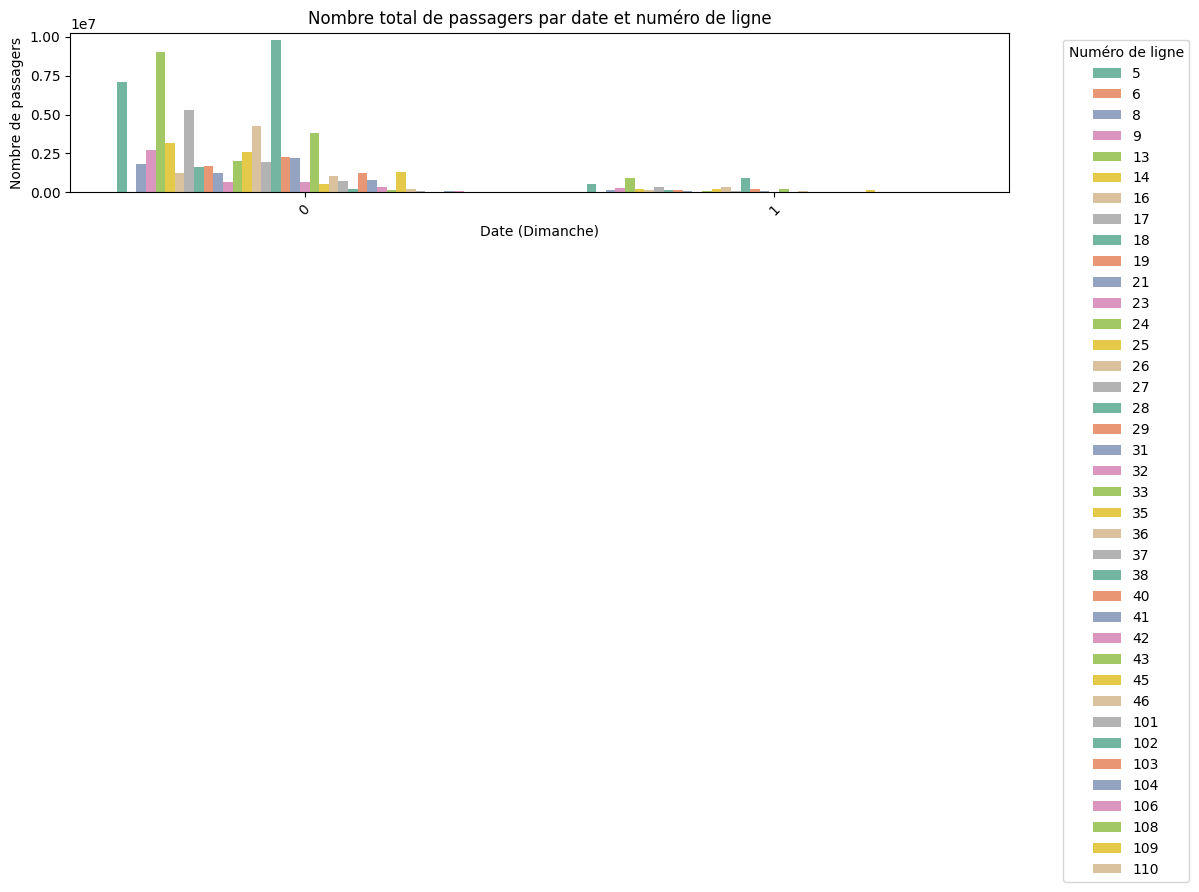

In [ ]:
Sunday_Passenger = data.groupby(['dateTimeIs_sunday', 'lineNumber'])['passengersNumber'].sum().reset_index()
# Création du bar plot
plt.figure(figsize=(12, 6))
sns.barplot(data=Sunday_Passenger, x="dateTimeIs_sunday", y="passengersNumber", hue="lineNumber", palette='Set2')

# Personnalisation du graphique
plt.xticks(rotation=45)
plt.title('Nombre total de passagers par date et numéro de ligne')
plt.xlabel('Date (Dimanche)')
plt.ylabel('Nombre de passagers')
plt.legend(title='Numéro de ligne', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()  # Pour ajuster le layout
plt.show()

In [ ]:
Sunday_Passenger

,dateTimeIs_sunday,lineNumber,passengersNumber
0,0,5,7099560
1,0,6,52266
2,0,8,1854752
3,0,9,2739499
4,0,13,9003197
...,...,...,...
72,1,104,4037
73,1,106,3259
74,1,108,2385
75,1,109,1559


<Axes: xlabel='dateTimeIs_holiday', ylabel='passengersNumber'>

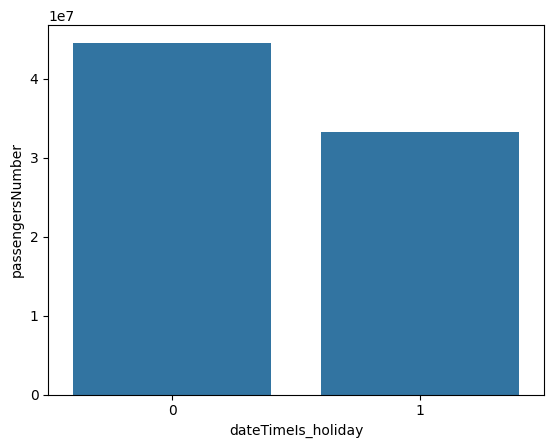

In [ ]:
holiday_Passenger = data.groupby("dateTimeIs_holiday")["passengersNumber"].sum().reset_index()
sns.barplot(holiday_Passenger, x="dateTimeIs_holiday", y ="passengersNumber")

<Axes: xlabel='dateTimeIs_paques', ylabel='passengersNumber'>

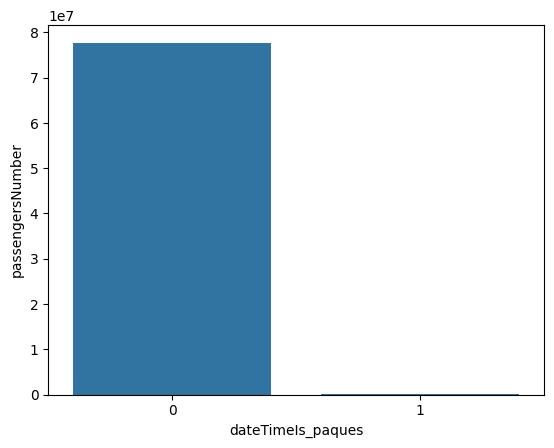

In [ ]:
paques_Passenger = data.groupby("dateTimeIs_paques")["passengersNumber"].sum().reset_index()
sns.barplot(paques_Passenger, x="dateTimeIs_paques", y ="passengersNumber")

In [ ]:
paques_Passenger

,dateTimeIs_paques,passengersNumber
0,0,77728975
1,1,69033


**Entrainement du modèle**

In [ ]:
X=data.drop('passengersNumber_+3_Days',axis=1)
y=data['passengersNumber_+3_Days']

In [ ]:
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2 ,random_state=42)


In [ ]:
X_sample, _, y_sample, _ = train_test_split(X_train, y_train, train_size=0.2, random_state=42)



In [ ]:
X['lineNumber'] = X['lineNumber'].astype('category')

In [ ]:
import xgboost
import sklearn

print("XGBoost version:", xgboost.__version__)
print("scikit-learn version:", sklearn.__version__)


XGBoost version: 1.6.2
scikit-learn version: 1.0.2


In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

# Paramètres à tester
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 10],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 5, 10],
    'gamma': [0, 0.1, 0.2],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5]
}


# Modèle XGBoost
xgb = XGBRegressor(random_state=42)

# GridSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=100,  # Nombre d'itérations à tester
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=2,
    n_jobs=-1,

)

# Entraînement
random_search.fit(X_sample, y_sample)

# Meilleurs hyperparamètres
print("Meilleurs paramètres :", random_search.best_params_)



Fitting 5 folds for each of 100 candidates, totalling 500 fits


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Failed to dlopen libcuda.so.1
  warnings.warn(str(e))


Meilleurs paramètres : {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 7, 'learning_rate': 0.1, 'gamma': 0.2, 'colsample_bytree': 1.0}


In [ ]:

# Paramètres à tester
params_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Modèle Random Forest
rf = RandomForestRegressor(random_state=42)

# GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=params_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=2,
    n_jobs=-1
)

# Entraînement
grid_search_rf.fit(X_sample, y_sample)

# Meilleurs hyperparamètres
print("Meilleurs paramètres pour Random Forest :", grid_search_rf.best_params_)


Fitting 5 folds for each of 54 candidates, totalling 270 fits
Meilleurs paramètres pour Random Forest : {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
from sklearn.ensemble import StackingRegressor

# 1. Séparer la colonne `lineNumber` avant la normalisation
line_number_train = X_train['lineNumber']
line_number_test = X_test['lineNumber']

X_train = X_train.drop('lineNumber', axis=1)
X_test = X_test.drop('lineNumber', axis=1)

# 2. Appliquer le codage des catégories sur `lineNumber`
line_number_train = line_number_train.astype('category').cat.codes
line_number_test = line_number_test.astype('category').cat.codes

# 3. Normalisation des autres caractéristiques
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Ajouter `lineNumber` transformé dans les données normalisées
X_train_scaled = np.column_stack((X_train_scaled, line_number_train))
X_test_scaled = np.column_stack((X_test_scaled, line_number_test))

# Si vous avez besoin de convertir en DataFrame pour garder les noms des colonnes :
X_train_scaled = pd.DataFrame(X_train_scaled, columns=list(X_train.columns) + ['lineNumber'])
X_test_scaled = pd.DataFrame(X_test_scaled, columns=list(X_test.columns) + ['lineNumber'])

# 5. Entraînement du modèle XGBoost
best =random_search.best_params_
model_xgb = XGBRegressor(objective='reg:squarederror', random_state=42, **best)
model_xgb.fit(X_train_scaled, y_train)
y_pred_xgb = model_xgb.predict(X_test_scaled)

# Calcul des métriques pour XGBoost
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

# 6. Entraînement du modèle LightGBM
model_lgb = lgb.LGBMRegressor(objective='regression', random_state=42)
model_lgb.fit(X_train_scaled, y_train, categorical_feature=['lineNumber'])
y_pred_lgb = model_lgb.predict(X_test_scaled)

# Calcul des métriques pour LightGBM
mse_lgb = mean_squared_error(y_test, y_pred_lgb)
rmse_lgb = np.sqrt(mse_lgb)
mae_lgb = mean_absolute_error(y_test, y_pred_lgb)
r2_lgb = r2_score(y_test, y_pred_lgb)

# Entraînement du modèle de régression linéaire
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

# Calcul des métriques pour la régression linéaire
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Entraînement du modèle Random Forest
best_params_rf = grid_search_rf.best_params_
rf_model = RandomForestRegressor(
    n_estimators=best_params_rf['n_estimators'],
    max_depth=best_params_rf['max_depth'],
    min_samples_split=best_params_rf['min_samples_split'],
    min_samples_leaf=best_params_rf['min_samples_leaf'],
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Calcul des métriques pour Random Forest
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)


#Modèle de stacking
estimators = [
    ('xgb', model_xgb),
    ('lgb', model_lgb),
    ('rf', rf_model)
]

stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator= LinearRegression(),  # Régression linéaire comme modèle final
    cv=5  # Cross-validation pour le modèle final
)

# Entraînement du modèle de stacking
stacking_model.fit(X_train, y_train)

# Prédictions du modèle de stacking
y_pred_stacking = stacking_model.predict(X_test)

# Calcul des métriques pour le modèle de stacking
mse_stacking = mean_squared_error(y_test, y_pred_stacking)
rmse_stacking = np.sqrt(mse_stacking)
mae_stacking = mean_absolute_error(y_test, y_pred_stacking)
r2_stacking = r2_score(y_test, y_pred_stacking)

# # Comparaison des résultats
# print("\n--- Résultats XGBoost ---")
# print(f"MSE: {mse_xgb}, RMSE: {rmse_xgb}, MAE: {mae_xgb}, R²: {r2_xgb}")

# print("\n--- Résultats LightGBM ---")
# print(f"MSE: {mse_lgb}, RMSE: {rmse_lgb}, MAE: {mae_lgb}, R²: {r2_lgb}")

# print("\n--- Résultats Régression Linéaire ---")
# print(f"MSE: {mse_lr}, RMSE: {rmse_lr}, MAE: {mae_lr}, R²: {r2_lr}")

# print("\n--- Résultats Random Forest ---")
# print(f"MSE: {mse_rf}, RMSE: {rmse_rf}, MAE: {mae_rf}, R²: {r2_rf}")

# Comparaison des résultats
results = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'Linear Regression', 'Random Forest', 'Stacking'],
    'MSE': [mse_xgb, mse_lgb, mse_lr, mse_rf, mse_stacking],
    'RMSE': [rmse_xgb, rmse_lgb, rmse_lr, rmse_rf, rmse_stacking],
    'MAE': [mae_xgb, mae_lgb, mae_lr, mae_rf, mae_stacking],
    'R²': [r2_xgb, r2_lgb, r2_lr, r2_rf, r2_stacking]
})

# Affichage des résultats
print(results)


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003110 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1446
[LightGBM] [Info] Number of data points in the train set: 30096, number of used features: 17
[LightGBM] [Info] Start training from score 2065.202120


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003319 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1398
[LightGBM] [Info] Number of data points in the train set: 30096, number of used features: 16
[LightGBM] [Info] Start training from score 2065.202120


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))
/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most rec

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002879 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1395
[LightGBM] [Info] Number of data points in the train set: 24076, number of used features: 16
[LightGBM] [Info] Start training from score 2073.438486
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002837 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1399
[LightGBM] [Info] Number of data points in the train set: 24077, number of used features: 16
[LightGBM] [Info] Start training from score 2068.453254
[LightGBM] [Warning] F

/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))
/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most rec

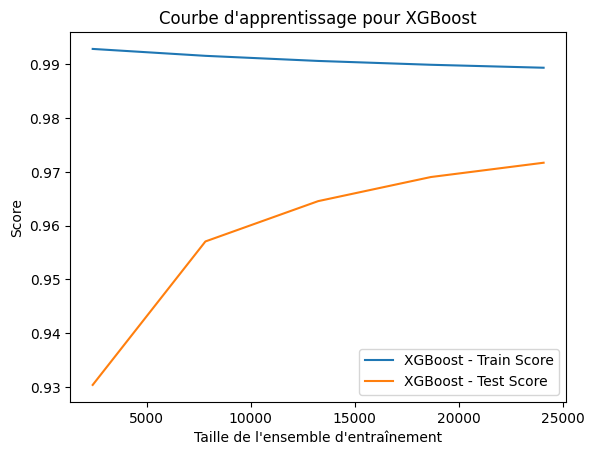

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
import numpy as np

# Fonction pour tracer les courbes d'apprentissage
def plot_learning_curve(model, X_train, y_train, model_name):
    train_sizes, train_scores, test_scores = learning_curve(model, X_train, y_train, cv=5)

    plt.plot(train_sizes, np.mean(train_scores, axis=1), label=f'{model_name} - Train Score')
    plt.plot(train_sizes, np.mean(test_scores, axis=1), label=f'{model_name} - Test Score')

# Tracer la courbe d'apprentissage pour XGBoost
plot_learning_curve(model_xgb, X_train_scaled, y_train, 'XGBoost')
plt.xlabel('Taille de l\'ensemble d\'entraînement')
plt.ylabel('Score')
plt.title('Courbe d\'apprentissage pour XGBoost')
plt.legend()
plt.show()


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000305 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1439
[LightGBM] [Info] Number of data points in the train set: 2407, number of used features: 16
[LightGBM] [Info] Start training from score 2026.633569
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001571 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1440
[LightGBM] [Info] Number of data points in the train set: 7824, number of used features: 16
[LightGBM] [Info] Start training from score 2054.806237
[LightGBM] [Warning] Fou

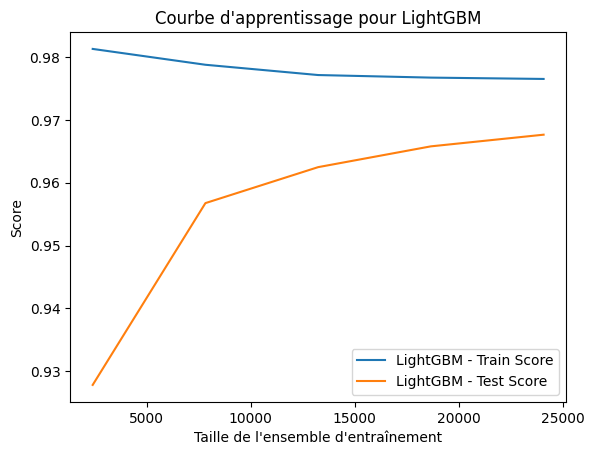

In [ ]:
# Tracer la courbe d'apprentissage pour LightGBM
plot_learning_curve(model_lgb, X_train_scaled, y_train, 'LightGBM')
plt.xlabel('Taille de l\'ensemble d\'entraînement')
plt.ylabel('Score')
plt.title('Courbe d\'apprentissage pour LightGBM')
plt.legend()
plt.show()


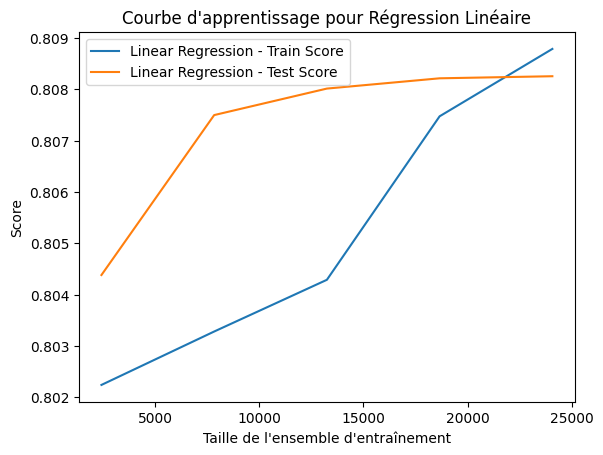

In [ ]:
# Tracer la courbe d'apprentissage pour la régression linéaire
plot_learning_curve(model_lr, X_train, y_train, 'Linear Regression')
plt.xlabel('Taille de l\'ensemble d\'entraînement')
plt.ylabel('Score')
plt.title('Courbe d\'apprentissage pour Régression Linéaire')
plt.legend()
plt.show()


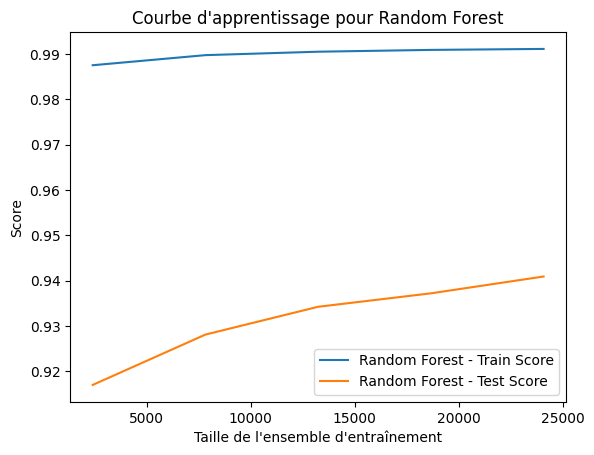

In [ ]:
# Tracer la courbe d'apprentissage pour Random Forest
plot_learning_curve(rf_model, X_train, y_train, 'Random Forest')
plt.xlabel('Taille de l\'ensemble d\'entraînement')
plt.ylabel('Score')
plt.title('Courbe d\'apprentissage pour Random Forest')
plt.legend()
plt.show()


In [ ]:
# Tracer la courbe d'apprentissage pour Stacking
plot_learning_curve(stacking_model, X_train, y_train, 'Stacking')
plt.xlabel('Taille de l\'ensemble d\'entraînement')
plt.ylabel('Score')
plt.title('Courbe d\'apprentissage pour Stacking')
plt.legend()
plt.show()


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000463 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1393
[LightGBM] [Info] Number of data points in the train set: 2407, number of used features: 15
[LightGBM] [Info] Start training from score 2026.633569


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))
/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most rec

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000362 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1394
[LightGBM] [Info] Number of data points in the train set: 1925, number of used features: 15
[LightGBM] [Info] Start training from score 2012.236364
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000368 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1392
[LightGBM] [Info] Number of data points in the train set: 1925, number of used features: 15
[LightGBM] [Info] Start training from score 2013.142338
[LightGBM] [Warning] Fou

/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))


...

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002910 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1399
[LightGBM] [Info] Number of data points in the train set: 24076, number of used features: 16
[LightGBM] [Info] Start training from score 2068.516656


/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))
/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most rec

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002350 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1396
[LightGBM] [Info] Number of data points in the train set: 19260, number of used features: 16
[LightGBM] [Info] Start training from score 2081.998235
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002366 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1399
[LightGBM] [Info] Number of data points in the train set: 19261, number of used features: 16
[LightGBM] [Info] Start training from score 2061.798401
[LightGBM] [Warning] F

/usr/local/lib/python3.10/dist-packages/cudf/utils/_ptxcompiler.py:64: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/usr/local/lib/python3.10/dist-packages/numba/cuda/cudadrv/driver.py", line 295, in __getattr__
    raise CudaSupportError("Error at driver init: \n%s:" %
numba.cuda.cudadrv.error.CudaSupportError: Error at driver init: 

CUDA driver library cannot be found.
If you are sure that a CUDA driver is installed,
try setting environment variable NUMBA_CUDA_DRIVER
with the file path of the CUDA driver shared library.
:


Not patching Numba
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.10/dist-packages/cudf/utils/gpu_utils.py:62: UserWarning: Function "cuInit" not found
  warnings.warn(str(e))


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000393 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1392
[LightGBM] [Info] Number of data points in the train set: 2407, number of used features: 15
[LightGBM] [Info] Start training from score 1962.653095
